<a href="https://colab.research.google.com/github/deva123932/CSA-4703-DL/blob/main/exp_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

```markdown
# Experiment 8: Two-Layer Neural Network with Backpropagation

In this notebook, we will build a 2-layer neural network (Input $\rightarrow$ Hidden $\rightarrow$ Output) from scratch using NumPy. We will manually derive and implement the forward and backward passes to solve non-linear classification tasks (XOR-style and Two-Moons datasets).
```

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

# Set random seed for reproducibility
np.random.seed(42)

```markdown
## 1. Dataset Generation
We generate both an XOR-style dataset and a Two-Moons dataset to test our non-linear classifier.
```

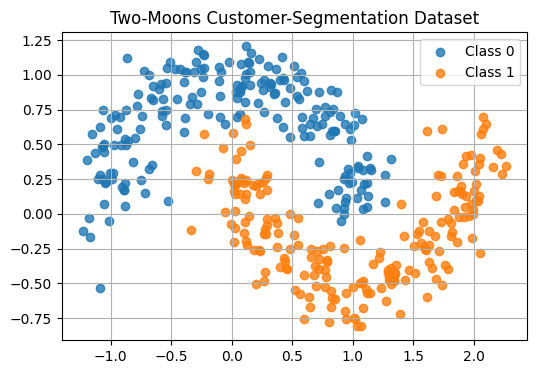

In [2]:
# Generate XOR-style dataset
def get_xor_data(num_samples=400):
    X = np.random.uniform(-1, 1, (num_samples, 2))
    # Label is 1 if inputs have different signs, else 0
    y = ( (X[:, 0] > 0) ^ (X[:, 1] > 0) ).astype(int).reshape(-1, 1)
    return X, y

# Generate Two-Moons dataset
def get_moons_data(num_samples=400):
    X, y = make_moons(n_samples=num_samples, noise=0.15, random_state=42)
    return X, y.reshape(-1, 1)

# Let's visualize the Two-Moons dataset
X_moons, y_moons = get_moons_data()
plt.figure(figsize=(6, 4))
plt.scatter(X_moons[y_moons.ravel()==0, 0], X_moons[y_moons.ravel()==0, 1], label='Class 0', alpha=0.8)
plt.scatter(X_moons[y_moons.ravel()==1, 0], X_moons[y_moons.ravel()==1, 1], label='Class 1', alpha=0.8)
plt.title("Two-Moons Customer-Segmentation Dataset")
plt.legend()
plt.grid(True)
plt.show()

```markdown
## 2. Neural Network Implementation
We define a class `TwoLayerNN` that implements forward propagation, backward propagation (analytical gradients), loss calculation, training loop, and numerical gradient verification.
```

In [3]:
class TwoLayerNN:
    def __init__(self, input_dim, hidden_dim, output_dim=1):
        # Task 1: Initialize weights and biases
        # Using He-like initialization scaling
        self.W1 = np.random.randn(input_dim, hidden_dim) * np.sqrt(2.0 / input_dim)
        self.b1 = np.zeros((1, hidden_dim))
        self.W2 = np.random.randn(hidden_dim, output_dim) * np.sqrt(2.0 / hidden_dim)
        self.b2 = np.zeros((1, output_dim))

    def sigmoid(self, z):
        return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))

    def sigmoid_derivative(self, a):
        # Given activation a = sigmoid(z), derivative is a * (1 - a)
        return a * (1.0 - a)

    def forward(self, X):
        # Task 2: Forward pass with sigmoid activations
        self.X = X
        self.z1 = np.dot(X, self.W1) + self.b1
        self.a1 = self.sigmoid(self.z1)
        self.z2 = np.dot(self.a1, self.W2) + self.b2
        self.a2 = self.sigmoid(self.z2)
        return self.a2

    def compute_loss(self, y_true, y_pred):
        # Binary Cross Entropy Loss
        m = y_true.shape[0]
        epsilon = 1e-15
        y_pred = np.clip(y_pred, epsilon, 1.0 - epsilon)
        loss = - (1.0 / m) * np.sum(y_true * np.log(y_pred) + (1.0 - y_true) * np.log(1.0 - y_pred))
        return loss

    def backward(self, y_true):
        # Task 3: Backward pass using the chain rule
        m = y_true.shape[0]

        # Output layer error
        da2 = -(y_true / (self.a2 + 1e-15) - (1.0 - y_true) / (1.0 - self.a2 + 1e-15))
        dz2 = da2 * self.sigmoid_derivative(self.a2) # Which simplifies to (self.a2 - y_true)

        # Gradients for layer 2
        self.dW2 = (1.0 / m) * np.dot(self.a1.T, dz2)
        self.db2 = (1.0 / m) * np.sum(dz2, axis=0, keepdims=True)

        # Hidden layer error
        da1 = np.dot(dz2, self.W2.T)
        dz1 = da1 * self.sigmoid_derivative(self.a1)

        # Gradients for layer 1
        self.dW1 = (1.0 / m) * np.dot(self.X.T, dz1)
        self.db1 = (1.0 / m) * np.sum(dz1, axis=0, keepdims=True)

    def update_weights(self, lr):
        self.W1 -= lr * self.dW1
        self.b1 -= lr * self.db1
        self.W2 -= lr * self.dW2
        self.b2 -= lr * self.db2

    def compute_numerical_gradient(self, X, y, param_name, index, epsilon=1e-5):
        # Helper to compute numerical gradient of one element of a weight matrix
        param = getattr(self, param_name)
        original_val = param[index]

        # Loss(theta + epsilon)
        param[index] = original_val + epsilon
        y_pred_plus = self.forward(X)
        loss_plus = self.compute_loss(y, y_pred_plus)

        # Loss(theta - epsilon)
        param[index] = original_val - epsilon
        y_pred_minus = self.forward(X)
        loss_minus = self.compute_loss(y, y_pred_minus)

        # Reset param
        param[index] = original_val

        # Centered difference formula
        grad_num = (loss_plus - loss_minus) / (2.0 * epsilon)
        return grad_num

```markdown
## 3. Verify Gradients Numerically
We compare the analytical gradient computed via backpropagation with the numerical gradient for a single weight to verify correctness.

In [4]:
# Initialize network and calculate gradients on small batch of data
model_test = TwoLayerNN(input_dim=2, hidden_dim=4, output_dim=1)
X_test, y_test = get_moons_data(10)

# Analytical gradient pass
y_pred = model_test.forward(X_test)
model_test.backward(y_test)

# Let's inspect W1[0, 0]
analytical_grad = model_test.dW1[0, 0]
numerical_grad = model_test.compute_numerical_gradient(X_test, y_test, 'W1', (0, 0))

print(f"Analytical gradient for W1[0,0]: {analytical_grad:.8f}")
print(f"Numerical gradient for W1[0,0]:  {numerical_grad:.8f}")
print(f"Absolute difference:           {abs(analytical_grad - numerical_grad):.8e}")

Analytical gradient for W1[0,0]: 0.02377218
Numerical gradient for W1[0,0]:  0.02377218
Absolute difference:           4.39846076e-12


```markdown
## 4. Model Training & Boundary Plotting Helper
We define a function to train the network on any dataset and plot the loss and decision boundary.

In [5]:
def train_and_visualize(X, y, hidden_dim=8, epochs=3000, lr=0.1, title_suffix=""):
    input_dim = X.shape[1]
    model = TwoLayerNN(input_dim=input_dim, hidden_dim=hidden_dim)

    loss_history = []
    for epoch in range(epochs):
        y_pred = model.forward(X)
        loss = model.compute_loss(y, y_pred)
        loss_history.append(loss)

        model.backward(y)
        model.update_weights(lr)

        if epoch % 500 == 0:
            print(f"Epoch {epoch}/{epochs} - Loss: {loss:.4f}")

    # Plotting
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Loss Plot
    ax1.plot(loss_history, color='tab:red')
    ax1.set_title(f"Loss vs Epochs {title_suffix}")
    ax1.set_xlabel("Epochs")
    ax1.set_ylabel("BCE Loss")
    ax1.grid(True)

    # Decision Boundary Plot
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))
    grid_points = np.c_[xx.ravel(), yy.ravel()]

    Z = model.forward(grid_points)
    Z = (Z > 0.5).astype(int)
    Z = Z.reshape(xx.shape)

    ax2.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.Spectral)
    scatter = ax2.scatter(X[:, 0], X[:, 1], c=y.ravel(), s=30, edgecolor='k', cmap=plt.cm.Spectral)
    ax2.set_title(f"Decision Boundary {title_suffix}")
    ax2.set_xlabel("Feature 1")
    ax2.set_ylabel("Feature 2")
    fig.tight_layout()
    plt.show()

```markdown
## 5. Training on Non-Linear Datasets
Now let's run the training loop and observe how our two-layer neural network with standard backpropagation dynamically captures the complex decision boundary.

Training on Two-Moons dataset...
Epoch 0/5000 - Loss: 0.6104
Epoch 500/5000 - Loss: 0.2883
Epoch 1000/5000 - Loss: 0.2474
Epoch 1500/5000 - Loss: 0.1584
Epoch 2000/5000 - Loss: 0.1105
Epoch 2500/5000 - Loss: 0.0836
Epoch 3000/5000 - Loss: 0.0666
Epoch 3500/5000 - Loss: 0.0556
Epoch 4000/5000 - Loss: 0.0482
Epoch 4500/5000 - Loss: 0.0429


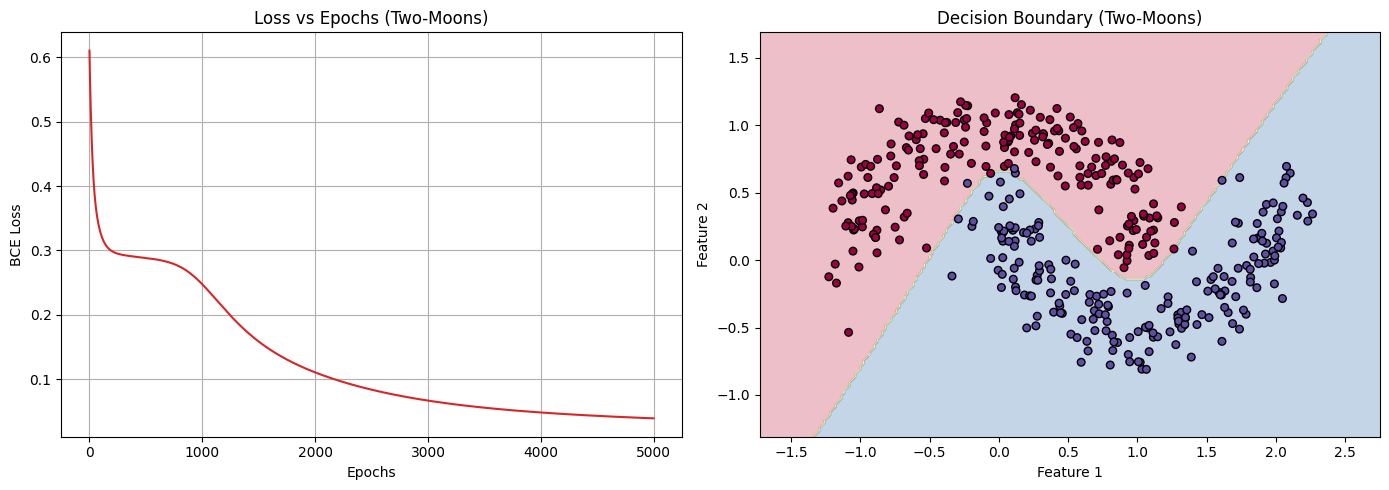

In [6]:
# Train on Two-Moons dataset
print("Training on Two-Moons dataset...")
X_moons, y_moons = get_moons_data()
train_and_visualize(X_moons, y_moons, hidden_dim=8, epochs=5000, lr=0.5, title_suffix="(Two-Moons)")

Training on XOR dataset...
Epoch 0/5000 - Loss: 0.7538
Epoch 500/5000 - Loss: 0.5025
Epoch 1000/5000 - Loss: 0.3047
Epoch 1500/5000 - Loss: 0.2316
Epoch 2000/5000 - Loss: 0.1810
Epoch 2500/5000 - Loss: 0.1420
Epoch 3000/5000 - Loss: 0.1184
Epoch 3500/5000 - Loss: 0.1042
Epoch 4000/5000 - Loss: 0.0945
Epoch 4500/5000 - Loss: 0.0873


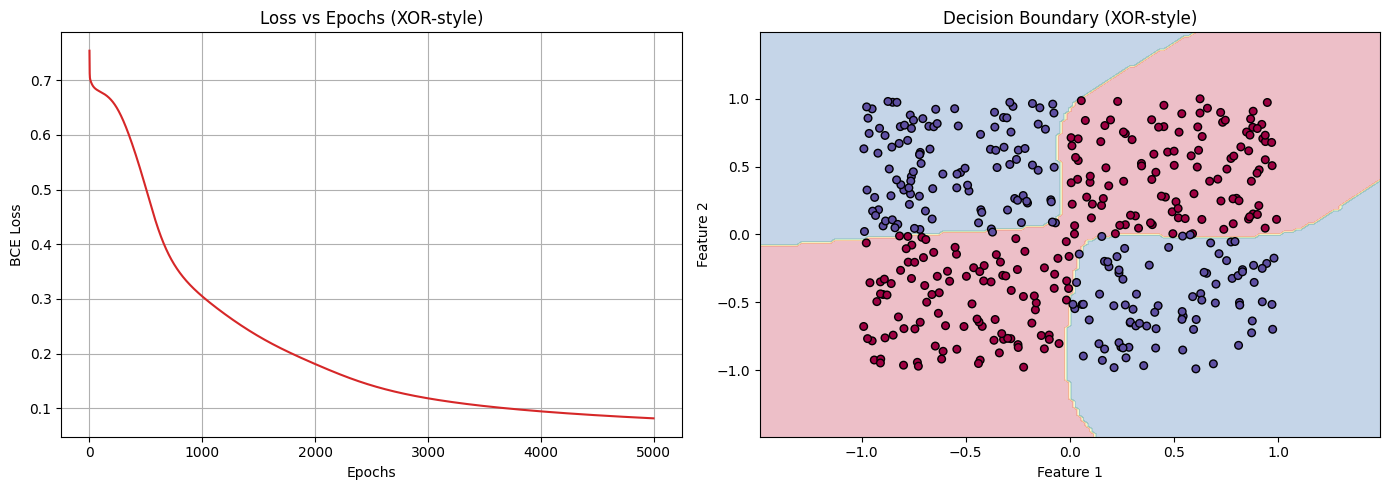

In [7]:
# Train on XOR-style dataset
print("Training on XOR dataset...")
X_xor, y_xor = get_xor_data()
train_and_visualize(X_xor, y_xor, hidden_dim=8, epochs=5000, lr=0.5, title_suffix="(XOR-style)")